# Ejercicio 2: modelo final DDQN para ejecución TWAP

**Modelo elegido:** DDQN con recompensa temporal cuadrática, gamma 0,99, batch 64 y 50.000 interacciones. La configuración completa aparece a continuación. En la calibración sobre REP `train` completa las 81 órdenes evaluadas con tres semillas; no se ha demostrado generalización fuera de muestra.

El notebook presenta primero el modelo final, su entrenamiento y sus gráficos. Después documenta las comparaciones que justifican la elección: recompensa y gamma con 100.000 pasos, y parámetros de entrenamiento con 50.000 pasos. Son dos presupuestos distintos, no una comparación directa entre sí.

**Bloques modificados:** referencia TWAP determinista, recompensa temporal, calibración, selección final y gráficos. Se reutilizan el entorno y el DDQN del equipo; se retiró la compra obligatoria inicial del agente. La exploración adaptativa y los checkpoints corresponden a la persona 3.


In [1]:
import pickle, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from src.agents.dqn import DDQNAgent
from src.agents.twap import twap_action
from src.environment.best_execution import BestExecutionEnv
from src.environment.config import EnvironmentConfig
from src.rewards import TwapRewardStrategy, VwapRewardStrategy

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'setup.py').exists())
with (root / 'data/rep_data.pkl').open('rb') as f:
    data = pickle.load(f)['train']
excluded_days = [day for day, frame in data.items() if (frame.cumvol.diff() < 0).any()]
print('Días excluidos por descenso de cumvol:', excluded_days)
data = {day: frame for day, frame in data.items() if day not in excluded_days}
print('Días de entrenamiento utilizados:', len(data))


Días excluidos por descenso de cumvol: [datetime.date(2018, 2, 12), datetime.date(2018, 3, 1)]
Días de entrenamiento utilizados: 58


## Estado, recompensa y configuración final

El estado contiene las fracciones de tiempo y volumen restantes. Su diferencia expresa la desviación entre progreso temporal y volumen ejecutado. La acción 0 espera y la 1 compra un título. La referencia determinista ejecuta $\lfloor Vt/H\rfloor$ títulos tras el paso $t$.

La recompensa elegida es $-(q_t/V-t/H)^2$. Se penaliza la fracción pendiente al finalizar. Si se completa antes del horizonte, se añade el error temporal de los pasos restantes con el mismo descuento del agente: finalizar pronto no oculta ese error. No se usan precios futuros para esta recompensa.

| Parámetro final | Valor | Motivación y evidencia |
|---|---:|---|
| Recompensa | Error temporal cuadrático negativo | La comparación inicial completa más órdenes que la absoluta; la recompensa considera el progreso después de cada acción. |
| Gamma | 0,99 | En la comparación inicial, la cuadrática con 0,99 completa 81/81 órdenes y con 0,999 completa 27/81. Gamma también cambia el descuento del error futuro terminal; no aislamos esos dos efectos. |
| Batch | **64** | En la calibración a 50.000 pasos completa 81/81 órdenes, frente a 27/81 con batch 32. El agente toma 63 experiencias aleatorias sin reemplazo y la última transición. Procesa más ejemplos por actualización, sin demostrar igual coste de cómputo. |
| Buffer | 2.000 | Equivale a 3,3–5 horizontes completos de 400–600 pasos y reutiliza experiencias recientes. El buffer de 8.000 solo completa 12/81 órdenes en la calibración. La capacidad no garantiza diversidad de estados o días. |
| Arquitectura | Dos capas de 32, ReLU | Dos entradas y dos valores Q de salida; 1.218 parámetros por red. Reducir a dos capas de 16 deja 354 parámetros, pero completa 0/81 órdenes en el piloto. No se demuestra que 32 sea el tamaño óptimo. |
| Adam: learning rate | 0,001 | Se conserva el valor del ejercicio 1, diez veces menor que el valor por defecto del constructor. Busca moderar las actualizaciones; no hemos comparado tasas ni demostrado que sea óptima. |
| Calentamiento | 256 pasos | Cuatro veces el batch final antes del aprendizaje. Aporta experiencias de la política aleatoria del entorno, sin garantizar cobertura del espacio de estados. |
| Aprendizaje | Cada 16 pasos | Produce 3.125 actualizaciones en 50.000 interacciones. Aprender cada 32 pasos reduce el trabajo a 1.562 actualizaciones, pero completa 18/81 órdenes en la calibración. |
| Copia objetivo | Cada 128 pasos | Mantiene la red objetivo fija durante ocho actualizaciones. Se conserva del ejercicio 1; no hemos comparado este intervalo por separado. |
| Presupuesto | **50.000 interacciones** | Es el presupuesto en el que hemos comparado batch 32 y 64. A él se suman 256 pasos de calentamiento. No es una prueba de convergencia ni una afirmación de que 50.000 supere a 100.000. |
| Epsilon | 1 → 0,05 lineal | Desciende durante las 50.000 interacciones. No implementa exploración adaptativa. |
| Semilla de la demostración | 11 | Primera de las semillas fijadas para los experimentos (11, 23 y 42), sin seleccionarla por su resultado. La calibración posterior muestra las tres. |

La configuración se eligió con los mismos escenarios de `train` que se muestran. Sus resultados son descriptivos de esos escenarios, no una validación independiente ni una búsqueda exhaustiva. Las tablas de calibración posteriores documentan también p90, peor error y variabilidad entre semillas.

Las variantes de buffer, anchura y frecuencia se compararon individualmente contra la base con batch 32. No se probaron sus interacciones con batch 64; la variante batch 64 conserva todos los demás parámetros de esa base.


In [2]:
STEPS = 100_000
SEEDS = (11, 23, 42)

def make_reward(kind, gamma):
    if kind == 'vwap':
        return VwapRewardStrategy()
    return TwapRewardStrategy(gamma=gamma, power=1 if kind == 'absolute' else 2)

def train(kind, gamma, seed, *, steps=STEPS, buffer_size=2000, batch_size=32,
          hidden_neurons=32, learn_every=16):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    env = BestExecutionEnv(data, EnvironmentConfig(seed=seed), make_reward(kind, gamma))
    agent = DDQNAgent(env, gamma=gamma, epsilon=1., alpha=.001, batch_size=batch_size,
                      buffer_size=buffer_size, hidden_neurons=hidden_neurons)
    s = env.reset()
    for _ in range(256):
        a = env.action_sample()
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        s = env.reset() if done else s1
    records, total, episode_steps = [], 0., 0
    s = env.reset()
    started = time.monotonic()
    for step in range(1, steps + 1):
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        total += r
        episode_steps += 1
        if step % learn_every == 0:
            agent.learn()
        if step % 128 == 0:
            agent.update_target()
        agent.epsilon = max(.05, 1 - .95 * step / steps)
        if done:
            records.append((step, total, episode_steps))
            s, total, episode_steps = env.reset(), 0., 0
        else:
            s = s1
    agent.set_trainable(False)
    print(kind, gamma, seed, 'segundos', round(time.monotonic()-started, 1), flush=True)
    return agent, pd.DataFrame(records, columns=['step', 'reward', 'episode_steps'])


## Episodios de comparación

Se excluyen los días cuyo volumen acumulado disminuye, ya que el entorno los rechaza. Se fijan tres días y tres posiciones de inicio, cruzados con tres duraciones y tres proporciones de orden. Cada ventana tiene exactamente la longitud necesaria, de modo que todas las políticas recorren las mismas filas. La evaluación usa `train` y no constituye una prueba fuera de muestra.


In [3]:
days = list(data)
cases = []
for horizon in (400, 500, 600):
    for fraction in (.075, .10, .125):
        volume = int(horizon * fraction)
        for day_index, position_fraction in ((0, .1), (len(days)//2, .5), (-1, .9)):
            day = days[day_index]
            frame = data[day]
            start = 60 + int((len(frame) - horizon - 60) * position_fraction)
            window = frame.iloc[start-60:start+horizon].copy()
            cases.append((day, start, horizon, volume, window))
assert len(cases) == 27

def evaluate(policy, case):
    day, start, horizon, volume, window = case
    # nextafter evita perder una unidad por redondeo en int(fracción * horizonte).
    fraction = np.nextafter(volume / horizon, 1.)
    cfg = EnvironmentConfig(look_back=60, min_episode_bins=horizon, max_episode_bins=horizon,
                            min_care_fraction=fraction, max_care_fraction=fraction, seed=7)
    env = BestExecutionEnv({day: window}, cfg, VwapRewardStrategy())
    s = env.reset()
    assert env.vol_care == volume
    if policy is not None:
        policy.env = env
    done = False
    while not done:
        action = twap_action(env) if policy is None else policy.act(s)
        s, _, done, _ = env.step(action)
    path = np.pad(np.cumsum(env.vol_hist), (0, horizon-env.state_pos), mode='edge') / volume
    ideal = np.arange(1, horizon+1) / horizon
    return {'day': day, 'start': start, 'horizon': horizon, 'volume': volume,
            'mae': np.mean(abs(path-ideal)), 'max_error': np.max(abs(path-ideal)),
            'complete': env.exec_vol == volume, 'finish_fraction': env.state_pos/horizon,
            'algo_vwap': env.algo_vwap_hist[-1], 'market_vwap': env.episode_vwap,
            'path': path, 'actions': np.array(env.actions_hist)}


## Entrenamiento y evaluación del modelo final

`FINAL_CONFIG` es la configuración usada para el modelo entregado. Reentrenamos una instancia con la semilla 11, la evaluamos en los 27 escenarios y conservamos `final_model` para sus gráficos. Las tres semillas de la calibración se presentan más abajo; esta demostración no añade una cuarta semilla independiente.


In [10]:
FINAL_CONFIG = dict(kind='squared', gamma=.99, seed=11, steps=50_000,
                    buffer_size=2000, batch_size=64, hidden_neurons=32, learn_every=16)
final_model, final_history = train(**FINAL_CONFIG)
final_results = pd.DataFrame([
    {key: value for key, value in evaluate(final_model, case).items()
     if key not in ('path', 'actions')}
    for case in cases
])
print('Configuración final:', FINAL_CONFIG)
print('Órdenes completas:', int(final_results.complete.sum()), '/', len(final_results))
display(pd.Series({
    'median_mae': final_results.mae.median(),
    'p90_mae': final_results.mae.quantile(.9),
    'worst_mae': final_results.mae.max(),
    'completion': final_results.complete.mean(),
}))


squared 0.99 11 segundos 32.3
Configuración final: {'kind': 'squared', 'gamma': 0.99, 'seed': 11, 'steps': 50000, 'buffer_size': 2000, 'batch_size': 64, 'hidden_neurons': 32, 'learn_every': 16}
Órdenes completas: 27 / 27


median_mae    0.011232
p90_mae       0.012341
worst_mae     0.012717
completion    1.000000
dtype: float64

## Resultados del modelo final

Se muestra la primera semilla fijada y un episodio representativo, junto a la referencia determinista. La tabla anterior cubre los 27 escenarios de esta instancia; las tablas de calibración posteriores muestran las tres semillas. El VWAP de mercado usa una aproximación con precio medio y volumen, no precios reales de transacción. La recompensa persigue una pauta temporal, no superar ese VWAP.


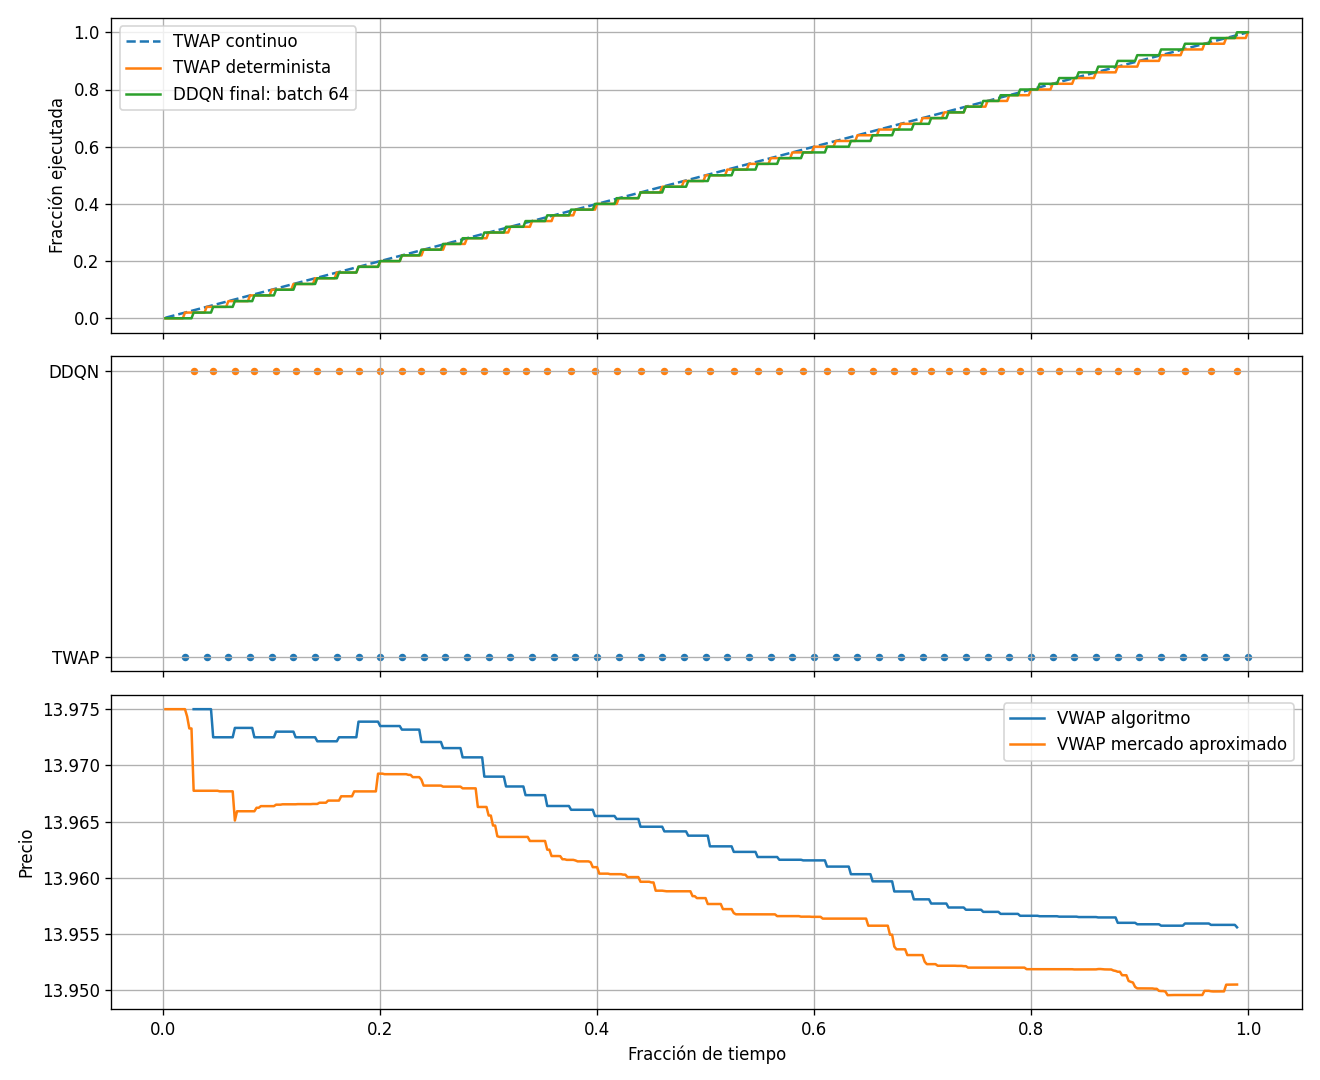

VWAP final del ejemplo: algoritmo 13.955599999999999 mercado aproximado del episodio completo 13.95047647099097


In [11]:
case = cases[13]
ref, learned = evaluate(None, case), evaluate(final_model, case)
h = case[2]
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
axes[0].plot(np.arange(1, h+1)/h, np.arange(1, h+1)/h, '--', label='TWAP continuo')
axes[0].plot(np.arange(1, h+1)/h, ref['path'], label='TWAP determinista')
axes[0].plot(np.arange(1, h+1)/h, learned['path'], label='DDQN final: batch 64')
axes[0].set_ylabel('Fracción ejecutada'); axes[0].legend(); axes[0].grid()
for offset, (label, item) in enumerate((('TWAP', ref), ('DDQN', learned))):
    positions = np.flatnonzero(item['actions']) + 1
    axes[1].scatter(positions/h, np.full(len(positions), offset), label=label, s=12)
axes[1].set_yticks([0, 1], ['TWAP', 'DDQN']); axes[1].grid()
env = final_model.env
time_axis = np.arange(1, env.state_pos+1) / h
algo_vwap = np.where(np.cumsum(env.vol_hist) > 0, env.algo_vwap_hist, np.nan)
axes[2].plot(time_axis, algo_vwap, label='VWAP algoritmo')
axes[2].plot(time_axis, env.market_vwap_hist, label='VWAP mercado aproximado')
axes[2].set_ylabel('Precio'); axes[2].set_xlabel('Fracción de tiempo')
axes[2].legend(); axes[2].grid()
plt.tight_layout(); plt.show()
print('VWAP final del ejemplo: algoritmo', learned['algo_vwap'],
      'mercado aproximado del episodio completo', learned['market_vwap'])


## Justificación de la elección: recompensas a 100.000 pasos

Cada entrenamiento recibe el mismo presupuesto de interacciones. Se informa mediana, percentil 90, peor error y tasa de finalización. La selección usa estos escenarios de entrenamiento, por lo que las cifras son descriptivas de ellos. Objetivo: al menos el 90 % de órdenes completas y mediana de error no superior a la referencia determinista más 0,05.

Esta fase previa usa batch 32 y 100.000 pasos. Sus salidas originales se conservan para justificar recompensa y gamma; no representan el modelo final presentado arriba.


In [4]:
models, histories, rows = {}, {}, []
for case in cases:
    rows.append(dict(evaluate(None, case), model='reference', gamma=np.nan, seed=np.nan))
for kind in ('vwap', 'absolute', 'squared'):
    for seed in SEEDS:
        model, history = train(kind, .99, seed)
        models[(kind, .99, seed)] = model
        histories[(kind, .99, seed)] = history
        for case in cases:
            rows.append(dict(evaluate(model, case), model=kind, gamma=.99, seed=seed))
results = pd.DataFrame(rows)
def summary(df):
    return df.groupby(['model', 'gamma'], dropna=False).agg(
        median_mae=('mae', 'median'), p90_mae=('mae', lambda x: x.quantile(.9)),
        worst_mae=('mae', 'max'), completion=('complete', 'mean'),
        median_finish=('finish_fraction', 'median'))
summary(results)


vwap 0.99 11 segundos 69.3


vwap 0.99 23 segundos 69.3


vwap 0.99 42 segundos 68.7


absolute 0.99 11 segundos 72.9


absolute 0.99 23 segundos 77.8


absolute 0.99 42 segundos 70.3


squared 0.99 11 segundos 74.5


squared 0.99 23 segundos 78.0


squared 0.99 42 segundos 77.1


,,median_mae,p90_mae,worst_mae,completion,median_finish
model,gamma,,,,,
absolute,0.99,0.015112,0.067667,0.069233,0.333333,1.0000
reference,NaN,0.009000,0.014592,0.016250,1.000000,1.0000
squared,0.99,0.019104,0.027644,0.028550,1.000000,0.9725
vwap,0.99,0.347560,0.388250,0.392351,0.666667,0.7780


### Comparación de gamma a 100.000 pasos

Se elige la recompensa temporal con menor mediana de error, exigiendo al menos un 90 % de finalización si alguna lo consigue. En caso de empate prevalece la absoluta. Después se cambia únicamente gamma. Estas elecciones y los objetivos anteriores se han fijado antes de observar los resultados.


In [5]:
candidates = summary(results).loc[['absolute', 'squared']].reset_index()
valid = candidates[candidates.completion >= .9]
if valid.empty:
    valid = candidates
chosen = valid.sort_values(['median_mae', 'model']).iloc[0]['model']
for seed in SEEDS:
    model, history = train(chosen, .999, seed)
    models[(chosen, .999, seed)] = model
    histories[(chosen, .999, seed)] = history
    for case in cases:
        rows.append(dict(evaluate(model, case), model=chosen, gamma=.999, seed=seed))
results = pd.DataFrame(rows)
print('Recompensa seleccionada:', chosen)
display(summary(results))


squared 0.999 11 segundos 73.8


squared 0.999 23 segundos 73.1


squared 0.999 42 segundos 69.7


Recompensa seleccionada: squared


median_mae   p90_mae  worst_mae  completion  median_finish
model     gamma                                                            
absolute  0.990    0.015112  0.067667   0.069233    0.333333         1.0000
reference NaN      0.009000  0.014592   0.016250    1.000000         1.0000
squared   0.990    0.019104  0.027644   0.028550    1.000000         0.9725
          0.999    0.018968  0.078300   0.080278    0.333333         1.0000
vwap      0.990    0.347560  0.388250   0.392351    0.666667         0.7780

### Estabilidad de la configuración inicial a 100.000 pasos

La misma recompensa puede funcionar de forma distinta según la inicialización. Se muestra cada semilla y los grupos de duración y tamaño CARE. Los resultados son sobre episodios de entrenamiento y no prueban generalización fuera de muestra. La comparación de gamma mantiene fija la recompensa seleccionada; se prioriza una finalización de al menos el 90 %, después el menor error mediano y, en caso de empate, el gamma menor.


In [6]:
gamma_summary = summary(results).loc[chosen].reset_index()
gamma_valid = gamma_summary[gamma_summary.completion >= .9]
if gamma_valid.empty:
    gamma_valid = gamma_summary
gamma_selected = float(gamma_valid.sort_values(['median_mae', 'gamma']).iloc[0]['gamma'])
selected = results[(results.model == chosen) & (results.gamma == gamma_selected)].copy()
selected['care_ratio'] = (selected.volume / selected.horizon).round(3)
print('Configuración elegida:', chosen, 'gamma =', gamma_selected)
print('Por semilla:')
display(selected.groupby('seed').agg(median_mae=('mae','median'), p90_mae=('mae', lambda x: x.quantile(.9)), completion=('complete','mean')))
print('Por duración y tamaño relativo de la orden:')
display(selected.groupby(['horizon','care_ratio']).agg(median_mae=('mae','median'), max_mae=('mae','max'), completion=('complete','mean')))
reference_median = results.loc[results.model == 'reference', 'mae'].median()
print('Finalización >= 90%:', selected.complete.mean() >= .9)
print('Error mediano <= referencia + 0,05:', selected.mae.median() <= reference_median + .05)


Configuración elegida: squared gamma = 0.99
Por semilla:


,median_mae,p90_mae,completion
seed,,,
11.0,0.019104,0.019591,1.0
23.0,0.027024,0.028289,1.0
42.0,0.009204,0.010234,1.0


Por duración y tamaño relativo de la orden:


median_mae   max_mae  completion
horizon care_ratio                                  
400     0.075         0.018333  0.024829         1.0
        0.100         0.018700  0.026050         1.0
        0.125         0.019150  0.027337         1.0
500     0.074         0.018434  0.025580         1.0
        0.100         0.019104  0.027024         1.0
        0.124         0.019482  0.028115         1.0
600     0.075         0.018698  0.026306         1.0
        0.100         0.019322  0.027644         1.0
        0.125         0.019756  0.028550         1.0

Finalización >= 90%: True
Error mediano <= referencia + 0,05: True


### Interpretación de la fase inicial a 100.000 pasos

Con las tres semillas y los 27 escenarios, la recompensa cuadrática con $\gamma=0{,}99$ completa las 81 órdenes y obtiene un error mediano de 0,0191; la referencia determinista obtiene 0,0090. El error máximo del agente es 0,0286. Cada semilla completa las 27 órdenes, aunque sus errores medianos varían entre 0,0092 y 0,0270.

La recompensa absoluta con $\gamma=0{,}99$ completa un tercio de los casos. Con la cuadrática, elevar $\gamma$ a 0,999 también reduce la tasa de finalización a un tercio. Estas observaciones motivan la elección de la recompensa cuadrática y $\gamma=0{,}99$ para este experimento; no prueban que estos valores sean óptimos en general.

Los datos utilizados son históricos de REP, sin impacto de mercado ni costes, y la evaluación está dentro de `train`. Los días 12 de febrero y 1 de marzo de 2018 se excluyeron por descensos de `cumvol`. No se ha demostrado generalización fuera de muestra.


## Calibración que determina el batch y presupuesto finales

Esta comparación amplía la calibración inicial con cinco configuraciones y tres semillas, fijadas antes de ejecutar. Conservamos recompensa cuadrática, gamma 0,99, Adam 0,001, calentamiento de 256 pasos y copia objetivo cada 128 pasos. Cada variante modifica un parámetro de la configuración base:

| Configuración | Cambio frente a base | Hipótesis que examinamos |
|---|---|---|
| base | Buffer 2.000, batch 32, dos capas de 32, aprendizaje cada 16 pasos | Control reentrenado con el presupuesto de esta comparación. |
| buffer_8000 | Buffer 8.000 | Más experiencias históricas pueden ayudar, aunque también se conservan experiencias más antiguas. |
| batch_64 | Batch 64 | Más ejemplos por actualización pueden reducir ruido, a costa de mayor trabajo por actualización. |
| hidden_16 | Dos capas de 16 | Una red menor podría bastar para las dos variables del estado. |
| learn_32 | Aprendizaje cada 32 pasos | Menos actualizaciones reducen trabajo, pero podrían perjudicar el aprendizaje. |

Se usan 50.000 interacciones por entrenamiento y las semillas 11, 23 y 42. Epsilon llega a 0,05 al final de esas 50.000 interacciones: baja el doble de rápido que en el experimento original. Por tanto, **no es un truncamiento ni una comparación directa con las corridas anteriores de 100.000 pasos**, cuyas salidas se conservan. El control se vuelve a entrenar aquí y el orden de variantes rota entre semillas.

Evaluamos los mismos 27 escenarios de `train`. Como el estado solo contiene tiempo y volumen, para una política determinista los tres días de cada par duración/volumen producen las mismas acciones: son nueve configuraciones temporales repetidas en tres ventanas de mercado, no 27 réplicas independientes. Las tres semillas son las repeticiones del entrenamiento; mostramos sus resultados por separado.

Antes de medir fijamos como criterios una finalización mínima del 90 % y MAE mediano no superior al de la referencia más 0,05; también informamos p90 y peor MAE. Este piloto se planteó inicialmente como análisis de sensibilidad. Tras obtener los resultados, seleccionamos batch 64 y su presupuesto evaluado de 50.000 pasos como configuración final de la entrega; no cambiamos retrospectivamente los criterios del piloto ni afirmamos que supere al modelo de 100.000 pasos. No prueba óptimos ni interacciones entre parámetros. Un barrido conjunto, otro algoritmo o un entrenador adaptativo quedan fuera de esta comparación.

El presupuesto de interacciones es igual, pero el trabajo de entrenamiento no: batch 64 duplica ejemplos por actualización y `learn_32` reduce las actualizaciones y deja cuatro, en vez de ocho, entre copias objetivo. Se informa el número de actualizaciones y los parámetros por red. La duración de la tabla incluye construcción del agente y calentamiento, excluye evaluación y es descriptiva de esta máquina compartida; no es una comparación de rendimiento controlada. El tiempo impreso dentro de `train()` solo mide su bucle principal.


In [8]:
import hashlib
import platform

print('Entorno:', platform.platform(), platform.machine())
print('Versiones:', 'Python', platform.python_version(), 'TF', tf.__version__,
      'NumPy', np.__version__, 'pandas', pd.__version__)
print('SHA256 REP:', hashlib.sha256((root / 'data/rep_data.pkl').read_bytes()).hexdigest())
print('Threads TF intra/inter:', tf.config.threading.get_intra_op_parallelism_threads(),
      tf.config.threading.get_inter_op_parallelism_threads())

sensitivity_steps = 50_000
variants = {
    'base': {},
    'buffer_8000': {'buffer_size': 8000},
    'batch_64': {'batch_size': 64},
    'hidden_16': {'hidden_neurons': 16},
    'learn_32': {'learn_every': 32},
}
sensitivity_rows, sensitivity_costs = [], []
reference_mae = np.median([evaluate(None, case)['mae'] for case in cases])
for index, seed in enumerate(SEEDS):
    names = list(variants)
    for name in names[index:] + names[:index]:
        settings = variants[name]
        started = time.monotonic()
        model, _ = train('squared', .99, seed, steps=sensitivity_steps, **settings)
        elapsed = time.monotonic() - started
        for case in cases:
            result = evaluate(model, case)
            sensitivity_rows.append({key: value for key, value in
                                     dict(result, config=name, seed=seed).items()
                                     if key not in ('path', 'actions')})
        sensitivity_costs.append(dict(config=name, seed=seed, seconds=elapsed,
                                      updates=sensitivity_steps // settings.get('learn_every', 16),
                                      parameters=model.primary_model.count_params()))
        print('Sensibilidad:', name, 'semilla', seed, flush=True)
sensitivity = pd.DataFrame(sensitivity_rows)
costs = pd.DataFrame(sensitivity_costs)


Entorno: macOS-27.0-arm64-arm-64bit arm64
Versiones: Python 3.11.15 TF 2.15.1 NumPy 1.26.4 pandas 2.0.3
SHA256 REP: c9b4d7d36783ef46f72bce5ac4fd8b952c7c8ab6c5d0d02f282f06f11e508426
Threads TF intra/inter: 1 1
squared 0.99 11 segundos 32.5
Sensibilidad: base semilla 11
squared 0.99 11 segundos 34.1
Sensibilidad: buffer_8000 semilla 11
squared 0.99 11 segundos 34.0
Sensibilidad: batch_64 semilla 11
squared 0.99 11 segundos 34.3
Sensibilidad: hidden_16 semilla 11
squared 0.99 11 segundos 26.9
Sensibilidad: learn_32 semilla 11
squared 0.99 23 segundos 33.6
Sensibilidad: buffer_8000 semilla 23
squared 0.99 23 segundos 32.9
Sensibilidad: batch_64 semilla 23
squared 0.99 23 segundos 34.3
Sensibilidad: hidden_16 semilla 23
squared 0.99 23 segundos 25.2
Sensibilidad: learn_32 semilla 23
squared 0.99 23 segundos 30.6
Sensibilidad: base semilla 23
squared 0.99 42 segundos 31.7
Sensibilidad: batch_64 semilla 42
squared 0.99 42 segundos 30.9
Sensibilidad: hidden_16 semilla 42
squared 0.99 42 segund

In [9]:
sensitivity_by_seed = sensitivity.groupby(['config', 'seed']).agg(
    median_mae=('mae', 'median'), p90_mae=('mae', lambda x: x.quantile(.9)),
    worst_mae=('mae', 'max'), completion=('complete', 'mean'))
sensitivity_summary = sensitivity.groupby('config').agg(
    median_mae=('mae', 'median'), p90_mae=('mae', lambda x: x.quantile(.9)),
    worst_mae=('mae', 'max'), completion=('complete', 'mean'))
sensitivity_summary['meets_targets'] = (
    (sensitivity_summary.completion >= .9) &
    (sensitivity_summary.median_mae <= reference_mae + .05))
sensitivity_summary = sensitivity_summary.join(costs.groupby('config').agg(
    updates=('updates', 'first'), parameters=('parameters', 'first'),
    median_seconds=('seconds', 'median')))
sensitivity_summary['mae_delta_vs_base'] = (
    sensitivity_summary.median_mae - sensitivity_summary.loc['base', 'median_mae'])
print('Referencia determinista: MAE mediano', reference_mae)
display(sensitivity_by_seed)
with pd.option_context('display.max_columns', None, 'display.width', 160):
    display(sensitivity_summary)


Referencia determinista: MAE mediano 0.008999999999999998


median_mae   p90_mae  worst_mae  completion
config      seed                                             
base        11      0.012988  0.013492   0.013671    0.000000
            23      0.020224  0.021943   0.022478    1.000000
            42      0.024560  0.026740   0.027367    0.000000
batch_64    11      0.011232  0.012341   0.012717    1.000000
            23      0.015900  0.016148   0.016246    1.000000
            42      0.016544  0.018233   0.018606    1.000000
buffer_8000 11      0.011978  0.013397   0.013987    0.000000
            23      0.051000  0.053316   0.053789    0.000000
            42      0.006250  0.008612   0.009763    0.444444
hidden_16   11      0.017552  0.019795   0.020696    0.000000
            23      0.014008  0.017505   0.019258    0.000000
            42      0.096952  0.098459   0.098850    0.000000
learn_32    11      0.051880  0.054070   0.054611    0.000000
            23      0.042360  0.044739   0.045411    0.000000
            42      0.016225  0.017116   0.017788    0.666667

,median_mae,p90_mae,worst_mae,completion,meets_targets,updates,parameters,median_seconds,mae_delta_vs_base
config,,,,,,,,,
base,0.019407,0.025750,0.027367,0.333333,False,3125,1218,32.207589,0.000000
batch_64,0.015791,0.017467,0.018606,1.000000,True,3125,1218,32.926041,-0.003617
buffer_8000,0.011978,0.052389,0.053789,0.148148,False,3125,1218,33.630600,-0.007430
hidden_16,0.018106,0.097756,0.098850,0.000000,False,3125,354,34.317185,-0.001302
learn_32,0.042360,0.053028,0.054611,0.222222,False,1562,1218,25.982608,0.022953


## Decisión final y límites

**En el presupuesto de 50.000 pasos, batch 64 es la única variante que cumple los dos criterios fijados.** Completa 81/81 órdenes evaluadas, con MAE mediano 0,0158 y p90 0,0175, frente a 27/81, MAE 0,0194 y p90 0,0258 del control reentrenado. Sus tres semillas completan todas sus órdenes; el control solo lo consigue con la semilla 23. Son tres entrenamientos por configuración, no 81 repeticiones independientes.

Ampliar el buffer a 8.000 consigue una mediana de error menor (0,0120), pero solo completa 12/81 órdenes y su p90 sube a 0,0524. Esta discrepancia muestra por qué no elegimos únicamente por MAE: una trayectoria próxima al objetivo puede dejar volumen pendiente. La red de 16 neuronas reduce los parámetros de 1.218 a 354, pero no completa ninguna orden en este piloto y su peor MAE es 0,0989. Aprender cada 32 pasos reduce las actualizaciones de 3.125 a 1.562 y completa 18/81 órdenes; su MAE mediano es 0,0424. Ninguna de estas alternativas demuestra una sustitución satisfactoria del control bajo los criterios fijados.

La conclusión es acotada: batch 64 consigue finalización completa en las tres semillas observadas, frente a una de tres con batch 32, con esta agenda de 50.000 pasos, a costa de procesar más ejemplos por actualización. No hemos demostrado mayor eficiencia de cómputo, significación estadística ni que la ventaja se mantenga a 100.000 pasos. Las diferencias entre semillas aconsejan conservar sus tablas junto al agregado.

Adoptamos batch 64 con 50.000 pasos para el modelo final presentado al principio. La fase inicial de 100.000 pasos conserva batch 32 y sus resultados como evidencia histórica; no se confunden las dos agendas de entrenamiento. Si se amplía la calibración, la siguiente comparación concreta sería batch 32 frente a 64 con 100.000 pasos, la misma agenda de epsilon y controles reentrenados. No se necesita incorporar el entrenador adaptativo de la persona 3 para justificar este análisis del ejercicio 2.
